In [97]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error

from pandas.plotting import autocorrelation_plot

# Formats floats to display with 2 decimal places and suppresses scientific notation
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# Data Loading

Loading the daily aggregated bicycle dataset, checking data types, checking for missing values, and viewing the first few rows.

In [98]:
bicycles = pd.read_csv('daily_trips.csv')

In [99]:
bicycles.info()

<class 'pandas.DataFrame'>
RangeIndex: 1461 entries, 0 to 1460
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0    1461 non-null   int64  
 1   starttime     1461 non-null   str    
 2   tripduration  1461 non-null   float64
 3   temperature   1458 non-null   float64
dtypes: float64(2), int64(1), str(1)
memory usage: 45.8 KB


In [100]:
bicycles.head()

,Unnamed: 0,starttime,tripduration,temperature
0,0,2014-01-01,1020.18,19.48
1,1,2014-01-02,1292.85,16.83
2,2,2014-01-03,58.38,-5.63
3,3,2014-01-04,2001.35,30.01
4,4,2014-01-05,393.13,16.76


# Preprocessing and Resampling

Converting the starttime column from text/object format into true Python datetime objects and setting it as the DataFrame's index.

Time-series models and pandas resampling methods require a chronological DatetimeIndex to properly understand time gaps, frequency, and temporal sequencing.

In [101]:
bicycles['starttime'] = pd.to_datetime(bicycles['starttime'], format ='%Y-%m-%d')

In [102]:
bicycles

,Unnamed: 0,starttime,tripduration,temperature
0,0,2014-01-01,1020.18,19.48
1,1,2014-01-02,1292.85,16.83
2,2,2014-01-03,58.38,-5.63
3,3,2014-01-04,2001.35,30.01
4,4,2014-01-05,393.13,16.76
...,...,...,...,...
1456,1456,2017-12-27,10348.68,2.46
1457,1457,2017-12-28,12129.60,10.80
1458,1458,2017-12-29,10690.93,12.98
1459,1459,2017-12-30,5054.87,3.66


In [103]:
bicycles_date = bicycles.set_index('starttime')

In [104]:
bicycles_date

,Unnamed: 0,tripduration,temperature
starttime,,,
2014-01-01,0,1020.18,19.48
2014-01-02,1,1292.85,16.83
2014-01-03,2,58.38,-5.63
2014-01-04,3,2001.35,30.01
2014-01-05,4,393.13,16.76
...,...,...,...
2017-12-27,1456,10348.68,2.46
2017-12-28,1457,12129.60,10.80
2017-12-29,1458,10690.93,12.98


Aggregating daily data into monthly totals.

In [105]:
series = bicycles_date['tripduration'].resample('1ME').sum()
series.info()

<class 'pandas.Series'>
DatetimeIndex: 48 entries, 2014-01-31 to 2017-12-31
Freq: ME
Series name: tripduration
Non-Null Count  Dtype  
--------------  -----  
48 non-null     float64
dtypes: float64(1)
memory usage: 768.0 bytes


In [106]:
series

starttime
2014-01-31    230623.63
2014-02-28    258834.20
2014-03-31    584575.37
2014-04-30   1159494.52
2014-05-31   1896429.25
2014-06-30   2510604.85
2014-07-31   3008273.27
2014-08-31   2714209.47
2014-09-30   2416844.15
2014-10-31   1910991.35
2014-11-30    980169.82
2014-12-31    740509.72
2015-01-31    528922.17
2015-02-28    324669.65
2015-03-31    902537.32
2015-04-30   1436105.67
2015-05-31   2272839.30
2015-06-30   3156543.45
2015-07-31   3850394.47
2015-08-31   3912334.13
2015-09-30   3448857.20
2015-10-31   2738624.93
2015-11-30   1737858.20
2015-12-31   1109834.97
2016-01-31    850457.87
2016-02-29   1048617.42
2016-03-31   1644324.52
2016-04-30   1990045.95
2016-05-31   3044007.22
2016-06-30   4275961.72
2016-07-31   4204210.50
2016-08-31   4153027.67
2016-09-30   3733713.72
2016-10-31   3055576.55
2016-11-30   2181343.95
2016-12-31    862949.82
2017-01-31   1021924.10
2017-02-28   1477708.20
2017-03-31   1396252.92
2017-04-30   2343807.63
2017-05-31   3030300.87
2017-0

Plotting the resulting time series.

<Axes: xlabel='starttime'>

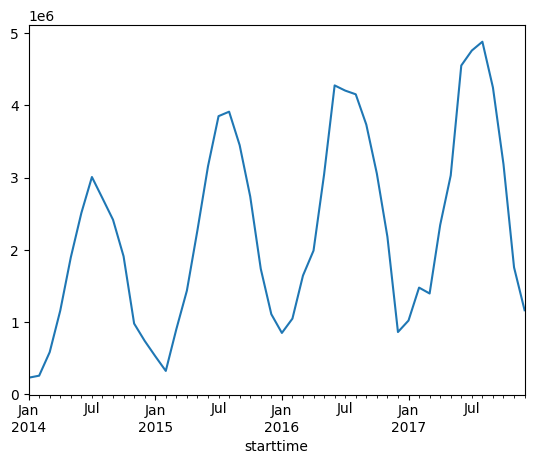

In [107]:
series.plot()

The line plot shows an upward trend over the years, accompanied by massive wave-like patterns (peaks in summer, drops in winter). This visual confirmation tells us the data is non-stationary (it has a trend and seasonality).

# Checking Stationarity and Differencing

A stationary time series has statistical properties—like mean and variance—that do not change over time. Most forecasting algorithms (like ARIMA) assume or require the data to be stationary to make reliable projections.

Running the Augmented Dickey-Fuller statistical test on our monthly series.

https://www.statsmodels.org/dev/generated/statsmodels.tsa.stattools.adfuller.html

In [108]:
from statsmodels.tsa.stattools import adfuller

adfuller(series)

(np.float64(-1.8346663570684087),
 np.float64(0.36339163599777635),
 10,
 37,
 {'1%': np.float64(-3.6209175221605827),
  '5%': np.float64(-2.9435394610388332),
  '10%': np.float64(-2.6104002410518627)},
 np.float64(1043.2726969809196))

The ADF test checks the null hypothesis that a time series is non-stationary.

Reading the output:
- If the p-value > 0.05, we fail to reject the null hypothesis -> Data is non-stationary. 
- If the p-value < 0.05, we reject the null hypothesis -> Data is stationary.

In [109]:
# test statistic
# pvalue
# number of lags used to determine t-statistics
# number of lags used in the analysis
# t valus at 1%, 5%, 10%

# pvalue > 0.05 ===> The null hypothesis cannot be rejected.

# Detrending

## Differentiating

In [110]:
series_df = pd.DataFrame(series)
series_df.head()

,tripduration
starttime,
2014-01-31,230623.63
2014-02-28,258834.20
2014-03-31,584575.37
2014-04-30,1159494.52
2014-05-31,1896429.25


Creating a lag-1 shifted column and subtracting it from the original series (first-order differencing), then re-testing and plotting.

Classical ARIMA models require a stationary mean. Differencing removes the underlying upward/downward trend.

In [111]:
series_df['shifted_1lag'] = series_df.shift(1)

In [112]:
series_df.head()

,tripduration,shifted_1lag
starttime,,
2014-01-31,230623.63,NaN
2014-02-28,258834.20,230623.63
2014-03-31,584575.37,258834.20
2014-04-30,1159494.52,584575.37
2014-05-31,1896429.25,1159494.52


In [113]:
series_df['series_diff'] = series_df['tripduration'] - series_df['shifted_1lag']
series_df.head()

,tripduration,shifted_1lag,series_diff
starttime,,,
2014-01-31,230623.63,NaN,NaN
2014-02-28,258834.20,230623.63,28210.57
2014-03-31,584575.37,258834.20,325741.17
2014-04-30,1159494.52,584575.37,574919.15
2014-05-31,1896429.25,1159494.52,736934.73


In [114]:
pvalue = adfuller(series_df['series_diff'][1:])[1]
pvalue

np.float64(8.437412867531849e-05)

In [115]:
if pvalue > 0.05:
    print('data is non-stationary')
else:
    print('data is stationary')

data is stationary


<Axes: xlabel='starttime'>

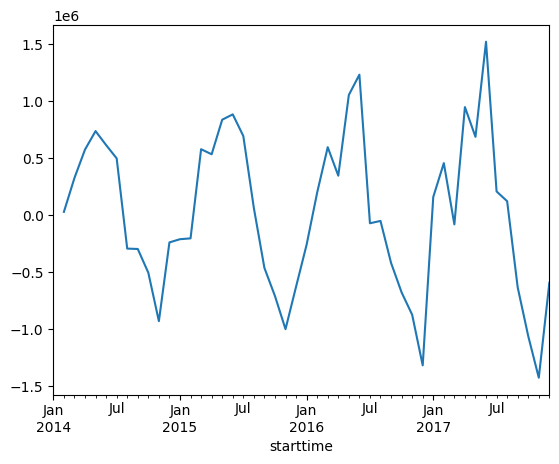

In [116]:
series_df['series_diff'].plot()

The differenced plot oscillates around a flat, constant mean (0), and the ADF test returns a p-value < 0.05, confirming our data is now stationary and ready for modeling.

Generating an autocorrelation (ACF) plot for the differenced data.

The ACF plot helps us visualise how past values correlate with current values.

<Axes: xlabel='Lag', ylabel='Autocorrelation'>

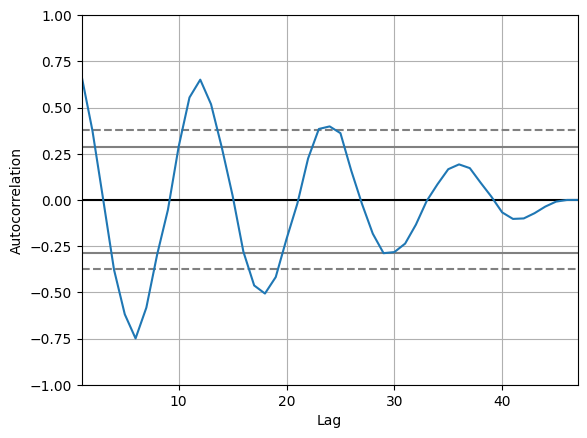

In [117]:
autocorrelation_plot(series_df['series_diff'][1:])

<Axes: xlabel='Lag', ylabel='Autocorrelation'>

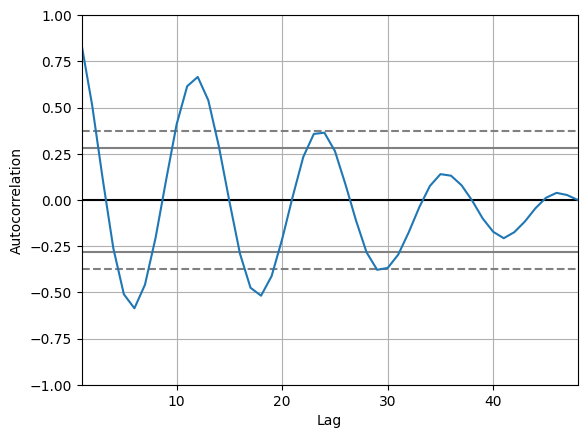

In [118]:
autocorrelation_plot(series_df['tripduration'])

In [119]:
series_df['tripduration'].describe()

count        48.00
mean    2264388.38
std     1341470.86
min      230623.63
25%     1094530.58
50%     2085694.95
75%     3163675.80
max     4880582.18
Name: tripduration, dtype: float64

In [120]:
series_df['series_diff'].describe()

count         47.00
mean       19871.23
std       691265.44
min     -1426866.82
25%      -484664.87
50%        28210.57
75%       576393.41
max      1521019.38
Name: series_diff, dtype: float64

# Task 1

# Task 2

# Experiment Tracking and Train-Test Split

In [121]:
series_df.head()

,tripduration,shifted_1lag,series_diff
starttime,,,
2014-01-31,230623.63,NaN,NaN
2014-02-28,258834.20,230623.63,28210.57
2014-03-31,584575.37,258834.20,325741.17
2014-04-30,1159494.52,584575.37,574919.15
2014-05-31,1896429.25,1159494.52,736934.73


In [122]:
series = series_df['tripduration']

Splitting the time series chronologically (training on data up through 2016, testing on the year 2017).

In time series, never use random splits (like train_test_split from sklearn). Random splitting causes data leakage, allowing the model to "peek" into the future. We must always train on the past and forecast the future.

In [123]:
train = series[:'2016-12-31']
test = series['2017-01-31':]

# ARIMA models

**AR----I----MA**

- AR - AutoRegressive model

- I - differentiate

- MA - Moving average

Setting up a centralised tracking table (results_df) and a helper function (log_experiment). We will log every model iteration and compare metrics (MAE, RMSE, and percentage-based MAPE) side-by-side without cluttering the notebook.

In [124]:
results_df = pd.DataFrame(columns=['Model', 'MAE', 'RMSE', 'MAPE'])

In [125]:
def log_experiment(df, model_name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred)
    
    new_row = pd.DataFrame({'Model': [model_name], 'MAE': [mae], 'RMSE': [rmse], 'MAPE': [mape]})
    return pd.concat([df, new_row], ignore_index=True)

MAPE measures prediction accuracy as a percentage. It tells us: 'On average, how far off are our predictions relative to the actual values in percentage terms?' It is exceptionally useful for business stakeholders who understand percentages better than absolute error units.

# Building Forecasting Models (AR & MA)

### AR(1)

In [126]:
from statsmodels.tsa.arima.model import ARIMA

Fitting an Autoregressive model of order 1 (ARIMA with p=1, d=0, q=0).

An AR model predicts future values using a linear combination of past values.

In [127]:
model = ARIMA(train, order = (1,0,0))
results = model.fit()

# p(AR), i, q(MA)

In [128]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:           tripduration   No. Observations:                   36
Model:                 ARIMA(1, 0, 0)   Log Likelihood                -531.836
Date:                Wed, 09 Sep 2026   AIC                           1069.671
Time:                        11:15:54   BIC                           1074.422
Sample:                    01-31-2014   HQIC                          1071.329
                         - 12-31-2016                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        2.08e+06   6.25e+05      3.330      0.001    8.56e+05     3.3e+06
ar.L1          0.8801      0.112      7.839      0.000       0.660       1.100
sigma2      3.688e+11      0.010   3.69e+13      0.000    3.69e+11    3.69e+11
===================================================================================
Ljung-Box (L1) (Q):                  17.62   Jarque-Bera (JB):                 0.65
Prob(Q):                              0.00   Prob(JB):                         0.72
Heteroskedasticity (H):               1.78   Skew:                             0.06
Prob(H) (two-sided):                  0.33   Kurtosis:                         2.35
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
[2] Covariance matrix is singular or near-singular, with condition number 1.36e+31. Standard errors may be unstable.
"""

In [129]:
train.mean()

np.float64(2079869.9421296294)

- Dep. Variable - The target time series being modeled (the endogenous variable).
- Model - The structure of the model identified by auto_arima. ARIMA(p, d, q).
- No. Observations - The number of data points used to train the model.
- Sample - The start and end dates of the training data.
- Log Likelihood - A measure of how well the model fits the data. Higher is better (less negative).
- Date/Time - The date and time the model was fitted.
  

- const - The model's intercept, or the baseline value when all other terms are zero.
- **ar.L1, coef - The coefficient for the first lag of the autoregressive term (AR(1)). It means the current value is strongly and positively related to the value one period ago.**
- sigma2 - The estimated variance of the model's residuals (the white noise/error term).
- P>|z|(P-value) - shows the significance of the predictor. Ideally, it should be less than 0.05, to be significant.

  
- AIC - Akaike information criterion - when comparing 2 models, the one with the lower AIC is generally "better". AIC penalises the complex models. If the orders are too high, we will get a high AIC.
- BIC - Bayesian information criterion - is similar to AIC. It penalises more the complex models than AIC.
- HQIC - Hannan-Quinn Information Criterion - Another alternative criterion, often falling between AIC and BIC in terms of penalty severity.

  
- Ljung-Box Test - **Prob(Q)** - p-value for Null hypothesis: The residuals are independently distributed (i.e., no serial correlation).
We want a large Prob(Q) (P-value) to fail to reject the null hypothesis.


- Jarque-Bera Test - **Prob(JB)** - p-value for Null hypothesis: The residuals are normally distributed.
We want a large Prob(JB) (P-value) to fail to reject the null hypothesis.


- Heteroskedasticity Test - **Prob(H)** - p-value for Null Hypothesis:The residuals have constant variance (homoscedasticity).
We want a large Prob(H) (P-value) to fail to reject the null hypothesis.

- Skewness measures whether our forecasting errors are symmetrically distributed around zero, or if the model tends to lean in one direction (bias). 
1. 0 Skew - Perfect symmetry. The model is equally likely to overestimate or underestimate the actual values, and the magnitude of those errors balances out.
2. Positive (Right) Skew - The error distribution has a long tail on the positive side. In forecasting, this means the model frequently underpredicts big spikes. For example, our bike rental model might consistently miss massive summer surge days, leaving large positive residual errors.
3. Negative (Left) Skew - The error distribution has a long tail on the negative side. This means the model frequently overpredicts drops or misses sudden downward crashes in demand.

If your errors lean strongly in one direction, your forecasts will have a built-in bias. This means business stakeholders who use these numbers may often be surprised by shortages or extra inventory.


- Kurtosis measures the "tailedness" of the error distribution. In other words, it shows how often extreme or unusual errors happen compared to a normal distribution.
1. Normal Kurtosis (approx. 3) - A standard bell curve has a baseline kurtosis of 3. Errors follow a predictable, well-behaved pattern.
2. High Kurtosis (Leptokurtic / "Fat Tails") - This means our distribution has high, sharp peaks around zero, but also unusually long, fat tails. In forecasting, fat tails mean extreme outlier errors happen much more often than normal statistics would predict.
3. Low Kurtosis (Platykurtic) - Errors are uniformly distributed with very few surprises or extreme values.

High kurtosis is a warning sign of model vulnerability to shocks. It tells you that while your model looks fine 90% of the time, it occasionally blows up and makes massive, catastrophic error spikes (e.g., severe unexpected weather events or sudden market shifts that the model couldn't anticipate).




For this very model our concerns are about the result of the Ljung-Box Test. This strongly suggests that your ARIMA(1, 0, 0) model is not capturing all the patterns in the data. The model is likely missing the seasonal component.

Generating out-of-sample predictions for 2017, plotting the confidence intervals against actual data, and logging error scores.

In [130]:
forecast = results.get_prediction(start = '2017-01-31', end = '2017-12-31')

In [131]:
forecast

In [132]:
forecast_mean = forecast.predicted_mean

In [133]:
forecast_mean

2017-01-31   1008798.85
2017-02-28   1137167.74
2017-03-31   1250151.50
2017-04-30   1349594.05
2017-05-31   1437118.31
2017-06-30   1514152.70
2017-07-31   1581954.45
2017-08-31   1641630.10
2017-09-30   1694153.56
2017-10-31   1740382.04
2017-11-30   1781069.99
2017-12-31   1816881.45
Freq: ME, Name: predicted_mean, dtype: float64

In [134]:
confidence_intervals = forecast.conf_int()

In [135]:
confidence_intervals

,lower tripduration,upper tripduration
2017-01-31,-181414.71,2199012.42
2017-02-28,-448392.55,2722728.04
2017-03-31,-583999.69,3084302.69
2017-04-30,-656062.48,3355250.58
2017-05-31,-691921.40,3566158.02
2017-06-30,-705758.47,3734063.88
2017-07-31,-705871.75,3869780.65
2017-08-31,-697452.25,3980712.45
2017-09-30,-683875.72,4072182.84
2017-10-31,-667384.96,4148149.03


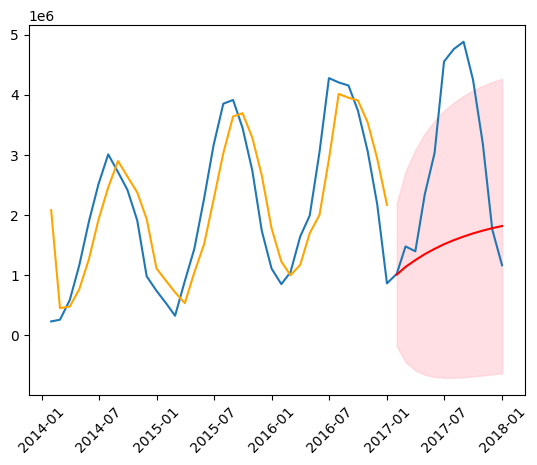

In [136]:
plt.plot(series)
plt.plot(results.fittedvalues, 
         color = 'orange', 
         label = 'forecast')
plt.plot(forecast_mean, color = 'red')
plt.fill_between(forecast_mean.index,
                confidence_intervals['lower tripduration'],
                confidence_intervals['upper tripduration'],
                color = 'pink',
                alpha = 0.5)
plt.xticks(rotation = 45);

The red forecast line tends to stay flat or drift linearly, failing to capture the massive seasonal swings of the actual data. This visually proves why baseline AR(1) is insufficient for seasonal data.

In [137]:
residuals = pd.DataFrame(forecast_mean)
residuals

,predicted_mean
2017-01-31,1008798.85
2017-02-28,1137167.74
2017-03-31,1250151.50
2017-04-30,1349594.05
2017-05-31,1437118.31
2017-06-30,1514152.70
2017-07-31,1581954.45
2017-08-31,1641630.10
2017-09-30,1694153.56
2017-10-31,1740382.04


In [138]:
residuals['actual_values'] = test

In [139]:
residuals

,predicted_mean,actual_values
2017-01-31,1008798.85,1021924.10
2017-02-28,1137167.74,1477708.20
2017-03-31,1250151.50,1396252.92
2017-04-30,1349594.05,2343807.63
2017-05-31,1437118.31,3030300.87
2017-06-30,1514152.70,4551320.25
2017-07-31,1581954.45,4758699.82
2017-08-31,1641630.10,4880582.18
2017-09-30,1694153.56,4246878.30
2017-10-31,1740382.04,3185072.85


In [140]:
residuals['error'] = np.absolute(residuals['predicted_mean'] - residuals['actual_values'])

In [141]:
residuals

,predicted_mean,actual_values,error
2017-01-31,1008798.85,1021924.10,13125.25
2017-02-28,1137167.74,1477708.20,340540.46
2017-03-31,1250151.50,1396252.92,146101.42
2017-04-30,1349594.05,2343807.63,994213.59
2017-05-31,1437118.31,3030300.87,1593182.56
2017-06-30,1514152.70,4551320.25,3037167.55
2017-07-31,1581954.45,4758699.82,3176745.36
2017-08-31,1641630.10,4880582.18,3238952.08
2017-09-30,1694153.56,4246878.30,2552724.74
2017-10-31,1740382.04,3185072.85,1444690.81


In [142]:
residuals['error'].mean()

np.float64(1434384.8229303602)

In [143]:
results_df = log_experiment(results_df, "AR_1", test, forecast_mean)

In [144]:
results_df

,Model,MAE,RMSE,MAPE
0,AR_1,1434384.82,1881946.06,0.41


### AR(2)

Upgrading to an AR(2) model ($p=2$) to look back two time steps.

We will test if adding more historical lag memory improves prediction accuracy and lowers our tracking table error metrics.

In [145]:
model = ARIMA(train, order = (2,0,0))
results = model.fit()

In [146]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:           tripduration   No. Observations:                   36
Model:                 ARIMA(2, 0, 0)   Log Likelihood                -508.495
Date:                Wed, 09 Sep 2026   AIC                           1024.989
Time:                        11:15:55   BIC                           1031.323
Sample:                    01-31-2014   HQIC                          1027.200
                         - 12-31-2016                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        2.08e+06   2.32e+05      8.974      0.000    1.63e+06    2.53e+06
ar.L1          1.6554      0.072     22.993      0.000       1.514       1.796
ar.L2         -0.8888      0.084    -10.618      0.000      -1.053      -0.725
sigma2      9.616e+10      0.025    3.8e+12      0.000    9.62e+10    9.62e+10
===================================================================================
Ljung-Box (L1) (Q):                   2.18   Jarque-Bera (JB):                 0.12
Prob(Q):                              0.14   Prob(JB):                         0.94
Heteroskedasticity (H):               2.14   Skew:                             0.11
Prob(H) (two-sided):                  0.20   Kurtosis:                         2.84
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
[2] Covariance matrix is singular or near-singular, with condition number 4.58e+29. Standard errors may be unstable.
"""

In [147]:
forecast = results.get_prediction(start = '2017-01-31', end = '2017-12-31')
forecast_mean = forecast.predicted_mean
confidence_intervals = forecast.conf_int()

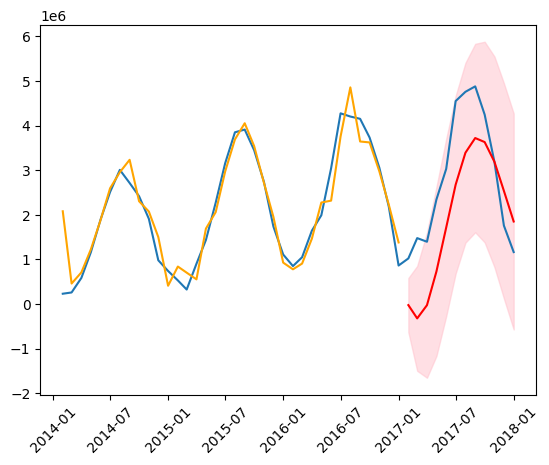

In [148]:
plt.plot(series)
plt.plot(results.fittedvalues, 
         color = 'orange', 
         label = 'forecast')
plt.plot(forecast_mean, color = 'red')
plt.fill_between(forecast_mean.index,
                confidence_intervals['lower tripduration'],
                confidence_intervals['upper tripduration'],
                color = 'pink',
                alpha = 0.5)
plt.xticks(rotation = 45);

In [149]:
results_df = log_experiment(results_df, "AR_2", test, forecast_mean)

In [150]:
results_df

,Model,MAE,RMSE,MAPE
0,AR_1,1434384.82,1881946.06,0.41
1,AR_2,1140284.63,1254249.78,0.54


AR_2 outperforms AR_1 across both absolute error metrics.
- MAE dropped from ~1,434,384 to ~1,140,284.
- RMSE dropped significantly from ~1,881,946 to ~1,254,249.


Adding a second lag (p=2 instead of p=1) gives the model slightly more memory of immediate past values, allowing it to track momentum a bit better. Because RMSE penalizes larger errors more heavily, the substantial drop in RMSE indicates that AR_2 makes fewer massive outlier mistakes than AR_1.

However, AR_1 has a better MAPE: 0.41 (41%) compared to AR_2's 0.54 (54%).

This creates a classic modeling trade-off: AR_2 is better at minimising total absolute volume errors (MAE/RMSE), but AR_1 occasionally yields lower relative percentage errors. Because MAPE divides errors by the actual values, points with smaller actual bike rentals can disproportionately inflate the percentage error.

## MA model

### MA(1)

Fitting a pure Moving Average model of order 1 (q=1).

While an AR model uses past values, an MA model uses past forecast errors (shocks or random white-noise residuals) to predict future values.

In [151]:
model = ARIMA(train, order = (0,0,1))
results = model.fit()
results.summary()

c:\Users\keiron.jones.TETRAD\Programming\Apprenticeship\venv\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:           tripduration   No. Observations:                   36
Model:                 ARIMA(0, 0, 1)   Log Likelihood                -542.799
Date:                Wed, 09 Sep 2026   AIC                           1091.598
Time:                        11:15:56   BIC                           1096.349
Sample:                    01-31-2014   HQIC                          1093.256
                         - 12-31-2016                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        2.08e+06   5.88e+05      3.536      0.000    9.27e+05    3.23e+06
ma.L1          0.9267      0.512      1.809      0.070      -0.077       1.931
sigma2      1.304e+12      0.003   3.85e+14      0.000     1.3e+12     1.3e+12
===================================================================================
Ljung-Box (L1) (Q):                  21.01   Jarque-Bera (JB):                 1.65
Prob(Q):                              0.00   Prob(JB):                         0.44
Heteroskedasticity (H):               1.47   Skew:                             0.17
Prob(H) (two-sided):                  0.51   Kurtosis:                         2.01
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
[2] Covariance matrix is singular or near-singular, with condition number 1.58e+33. Standard errors may be unstable.
"""

Look at the ma.L1 coefficient and its p-value. Like our previous models, the summary metrics and high errors highlight that a simple MA model alone cannot capture the powerful growth trend and annual seasonality present in our monthly bicycle data.

Extracting out-of-sample predictions and their upper/lower confidence bounds for the year 2017 using our fitted MA(1) model.

Point predictions (the mean) tell us the expected value, but confidence intervals give us a statistical boundary of uncertainty—crucial for real-world planning.

In [152]:
forecast = results.get_prediction(start = '2017-01-31', end = '2017-12-31')
forecast_mean = forecast.predicted_mean
confidence_intervals = forecast.conf_int()

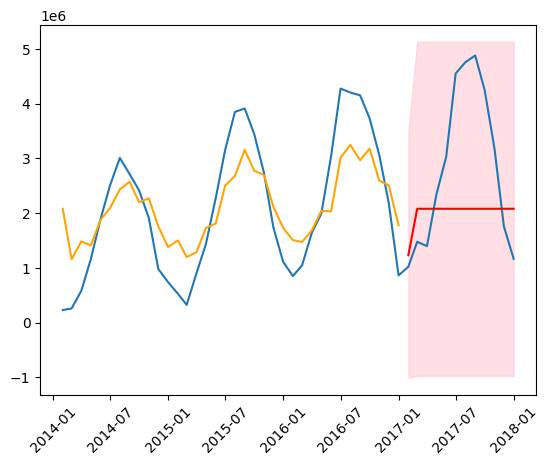

In [153]:
plt.plot(series)
plt.plot(results.fittedvalues, 
         color = 'orange', 
         label = 'forecast')
plt.plot(forecast_mean, color = 'red')
plt.fill_between(forecast_mean.index,
                confidence_intervals['lower tripduration'],
                confidence_intervals['upper tripduration'],
                color = 'pink',
                alpha = 0.5)
plt.xticks(rotation = 45);

Notice how the MA(1) forecast flattens out quickly. Without an Autoregressive component or differencing, the Moving Average model quickly reverts to the mean, proving it is blind to long-term trends.

In [154]:
results_df = log_experiment(results_df, "MA_1", test, forecast_mean)

In [155]:
results_df

,Model,MAE,RMSE,MAPE
0,AR_1,1434384.82,1881946.06,0.41
1,AR_2,1140284.63,1254249.78,0.54
2,MA_1,1264229.03,1576758.78,0.42


## ARMA

Fitting an ARIMA model where $d = 1$ (the "Integrated" component), meaning the model automatically applies first-order differencing to the training data before fitting the AR and MA terms.

As we saw earlier, our raw bicycle series is non-stationary due to its upward trend. Instead of manually differencing outside the model, ARIMA handles it internally, ensuring predictions are projected back onto the original scale.

In [156]:
model = ARIMA(train, order = (1,1,1))
results = model.fit()
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:           tripduration   No. Observations:                   36
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -501.772
Date:                Wed, 09 Sep 2026   AIC                           1009.545
Time:                        11:15:57   BIC                           1014.211
Sample:                    01-31-2014   HQIC                          1011.155
                         - 12-31-2016                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.7021      0.145      4.851      0.000       0.418       0.986
ma.L1          0.2631      0.278      0.947      0.343      -0.281       0.807
sigma2       1.82e+11   2.35e-13   7.75e+23      0.000    1.82e+11    1.82e+11
===================================================================================
Ljung-Box (L1) (Q):                   0.01   Jarque-Bera (JB):                 0.15
Prob(Q):                              0.94   Prob(JB):                         0.93
Heteroskedasticity (H):               2.11   Skew:                            -0.08
Prob(H) (two-sided):                  0.21   Kurtosis:                         2.72
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
[2] Covariance matrix is singular or near-singular, with condition number 1.46e+40. Standard errors may be unstable.
"""

In [157]:
forecast = results.get_prediction(start = '2017-01-31', end = '2017-12-31')
forecast_mean = forecast.predicted_mean
confidence_intervals = forecast.conf_int()

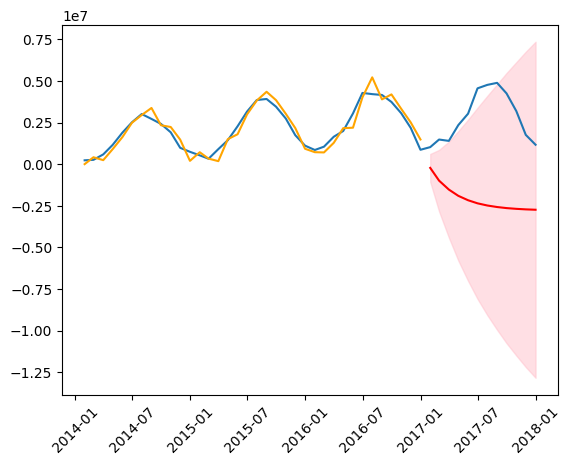

In [158]:
plt.plot(series)
plt.plot(results.fittedvalues, 
         color = 'orange', 
         label = 'forecast')
plt.plot(forecast_mean, color = 'red')
plt.fill_between(forecast_mean.index,
                confidence_intervals['lower tripduration'],
                confidence_intervals['upper tripduration'],
                color = 'pink',
                alpha = 0.5)
plt.xticks(rotation = 45);

In [159]:
results_df = log_experiment(results_df, "ARMA_(1,1,1)", test, forecast_mean)

In [160]:
results_df

,Model,MAE,RMSE,MAPE
0,AR_1,1434384.82,1881946.06,0.41
1,AR_2,1140284.63,1254249.78,0.54
2,MA_1,1264229.03,1576758.78,0.42
3,"ARMA_(1,1,1)",4900807.84,5275637.72,1.87


# Task 3

# ACF and PACF

Before choosing the orders for an ARIMA model (p for AR, q for MA), we need a mathematical tool to inspect how data points relate to their past values (lags). This is where ACF and PACF plots come in.

Compute ACF and PACF values only on stationary data.(!)

**The goal is to find the lag where each plot cuts off, meaning - becomes statistically insignificant, remaining within the blue shaded area.**

## ACF Plot (for MA Order q)

ACF calculates the correlation between the current series and a lagged version of itself across multiple time steps (lags). Crucially, ACF measures the total correlation, which includes both direct relationships and indirect relationships passed through intermediate lags.

In a time series with strong seasonality or a trend, the ACF plot typically shows a very slow, gradual decay or massive repeating waves across long lags.

ACF helps determine the Moving Average ($q$) order. Typically, if the ACF cuts off sharply after a specific lag $p$ (or drops into the confidence interval), it suggests an MA($q$) signature.

In [161]:
from statsmodels.graphics.tsaplots import plot_acf

In [162]:
series_df.head()

,tripduration,shifted_1lag,series_diff
starttime,,,
2014-01-31,230623.63,NaN,NaN
2014-02-28,258834.20,230623.63,28210.57
2014-03-31,584575.37,258834.20,325741.17
2014-04-30,1159494.52,584575.37,574919.15
2014-05-31,1896429.25,1159494.52,736934.73


In [163]:
series_df['series_diff'].head()

starttime
2014-01-31         NaN
2014-02-28    28210.57
2014-03-31   325741.17
2014-04-30   574919.15
2014-05-31   736934.73
Freq: ME, Name: series_diff, dtype: float64

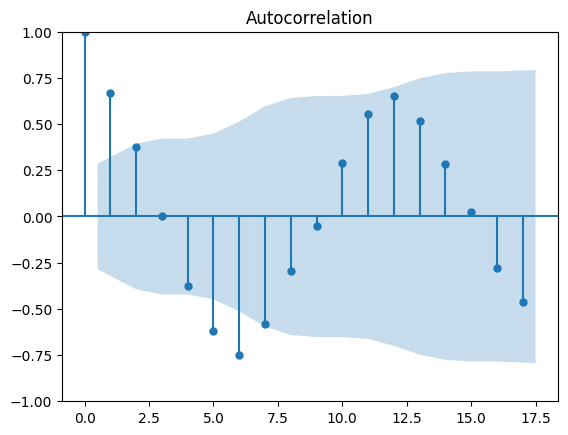

In [164]:
plot_acf(series_df['series_diff'][1:]);

The ACF shows significant spikes that decay slowly and oscillate (lags 2, 5, 6).

Because the ACF decays gradually rather than cutting off sharply, this is a strong indication that an AutoRegressive (AR) component (p > 0) is present.

**A decaying ACF suggests that the Moving Average order q should be 0** (or a very small number like 1, if there is a slight "tail" in the PACF).

## PACF Plot (for AR Order p)

PACF measures the correlation between the series and a lagged version while stripping out (controlling for) the intermediate correlations of the intervening lags. It isolates the direct relationship between lag $k$ and the current time step.

If lag 1 has a strong relationship with lag 2, the ACF will show lag 2 as important just because it correlates with lag 1. The PACF cuts through that noise to show whether lag 2 has an independent, direct effect on the present.

PACF helps determine the Autoregressive ($p$) order. If the PACF cuts off abruptly after lag $p$, that suggests an AR($p$) model is appropriate.

In [165]:
from statsmodels.graphics.tsaplots import plot_pacf

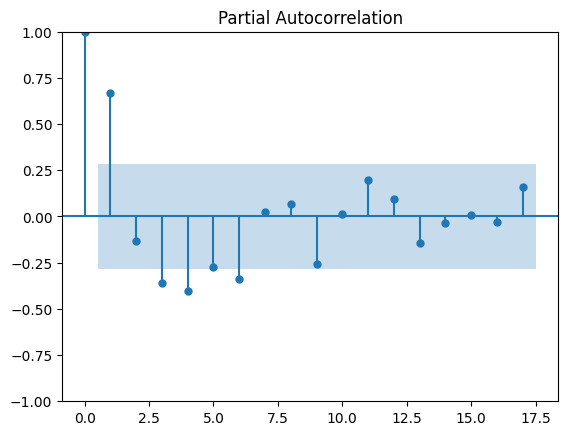

In [166]:
plot_pacf(series_df['series_diff'][1:]);

A clear AR(p) process has p consecutive significant spikes followed by an immediate cut-off.

Here the we have a cut-off after the lag 1.

In conclusion:
AR(p) is most likely greater than 0. p is a strong 1, but we might try values closer to 1. And we've actually seen that p=2 performs better.

Also, it is worth trying: 
- ARMA(2, 1)
- ARIMA(1,d,1)
- ARIMA(2,d,1)
- ARIMA(1,d,0)
- ARIMA(2,d,0)

However, from our EDA, we know that we have a strong seasonality in the data. 

We must integrate a seasonal component by using a Seasonal ARIMA (SARIMA) model, denoted as SARIMA(p, d, q)(P, D, Q)s.

# Task 4

## SARIMA

<Axes: xlabel='starttime'>

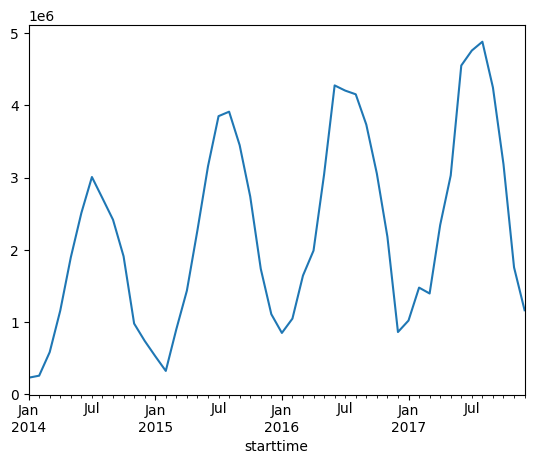

In [167]:
series.plot()

Upgrading from standard ARIMA to SARIMA by adding a seasonal_order tuple (P, D, Q, s). Here, s=12 represents our 12-month annual cycle.

Earlier, our residual and Ljung-Box tests proved that non-seasonal models were failing because they ignored the massive summer peaks and winter drops. SARIMA explicitly models these repeating annual patterns.

In [168]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

**SARIMAX(p, d,q)(P, D, Q)s**

s - number of lags. For example, s=7 => we will use the values from one week ago to forecast the tomorrow's value.

In [169]:
model = SARIMAX(endog=train,
              order=(2, 1, 0),
              seasonal_order=(1, 0, 0, 12))
results = model.fit()

c:\Users\keiron.jones.TETRAD\Programming\Apprenticeship\venv\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:997: UserWarning: Non-stationary starting seasonal autoregressive Using zeros as starting parameters.
  warn('Non-stationary starting seasonal autoregressive'


In [170]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                     SARIMAX Results                                      
==========================================================================================
Dep. Variable:                       tripduration   No. Observations:                   36
Model:             SARIMAX(2, 1, 0)x(1, 0, 0, 12)   Log Likelihood                -498.336
Date:                            Wed, 09 Sep 2026   AIC                           1004.671
Time:                                    11:15:58   BIC                           1010.893
Sample:                                01-31-2014   HQIC                          1006.819
                                     - 12-31-2016                                         
Covariance Type:                              opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.7140      0.324      2.206      0.027       0.080       1.348
ar.L2         -0.0921      0.342     -0.269      0.788      -0.763       0.579
ar.S.L12       0.5537      0.309      1.793      0.073      -0.052       1.159
sigma2      1.666e+11   5.92e-13   2.82e+23      0.000    1.67e+11    1.67e+11
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):                 2.30
Prob(Q):                              0.99   Prob(JB):                         0.32
Heteroskedasticity (H):               2.24   Skew:                            -0.61
Prob(H) (two-sided):                  0.18   Kurtosis:                         3.27
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
[2] Covariance matrix is singular or near-singular, with condition number 1.39e+40. Standard errors may be unstable.
"""

In [171]:
forecast = results.get_prediction(start = '2017-01-31', end = '2017-12-31')
forecast_mean = forecast.predicted_mean
confidence_intervals = forecast.conf_int()

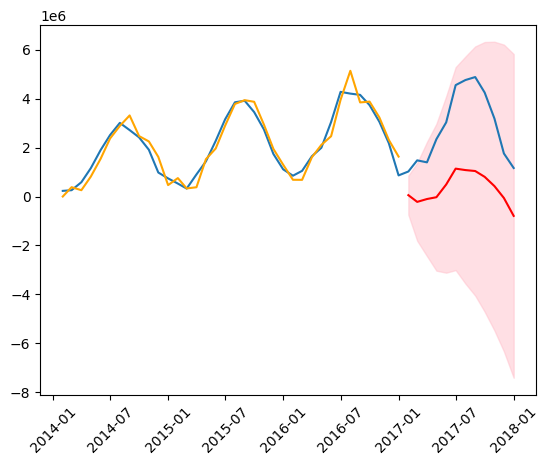

In [172]:
plt.plot(series)
plt.plot(results.fittedvalues, 
         color = 'orange', 
         label = 'forecast')
plt.plot(forecast_mean, color = 'red')
plt.fill_between(forecast_mean.index,
                confidence_intervals['lower tripduration'],
                confidence_intervals['upper tripduration'],
                color = 'pink',
                alpha = 0.5)
plt.xticks(rotation = 45);

In [173]:
results_df = log_experiment(results_df, "SARIMA(2, 1, 0)x(1, 0, 0, 12)", test, forecast_mean)

In [174]:
results_df

,Model,MAE,RMSE,MAPE
0,AR_1,1434384.82,1881946.06,0.41
1,AR_2,1140284.63,1254249.78,0.54
2,MA_1,1264229.03,1576758.78,0.42
3,"ARMA_(1,1,1)",4900807.84,5275637.72,1.87
4,"SARIMA(2, 1, 0)x(1, 0, 0, 12)",2498350.29,2655982.78,0.98


## Auto ARIMA

Using the pmdarima library to run an automated grid search (auto_arima) across various combinations of p, d, and q.

Manually guessing optimal lag orders using ACF and PACF plots can be subjective and time-consuming. auto_arima loops through combinations and selects the model with the lowest AIC score automatically.

The trace=True argument prints out the AIC values for every model tested. The final summary will display the winning ARIMA(p,d,q) configuration chosen by the algorithm.

In [175]:
import pmdarima as pmd

https://alkaline-ml.com/pmdarima/modules/generated/pmdarima.arima.auto_arima.html

In [176]:
auto_arima_model = pmd.auto_arima(train,
                         start_p=0,  # initial guess for AR(p)
                         start_d=0,  # initial guess for I(d)
                         start_q=0,  # initial guess for MA(q)
                         max_p=5,    # max guess for AR(p)
                         max_d=2,    # max guess for I(d)
                         max_q=5,    # max guess for MA(q)
                         m=12,        # seasonal order
                         start_P=0,  # initial guess for seasonal AR(P)
                         start_D=0,  # initial guess for seasonal I(D)
                         start_Q=0,  # initial guess for seasonal MA(Q)
                         max_P = 3,
                         max_D = 1,
                         max_Q = 3,
                         information_criterion='bic',
                         trace=True,
                         error_action='ignore',
                         stepwise = False
                         )

 ARIMA(0,0,0)(0,1,0)[12] intercept   : BIC=685.531, Time=0.03 sec
 ARIMA(0,0,0)(0,1,1)[12] intercept   : BIC=684.429, Time=0.06 sec
 ARIMA(0,0,0)(0,1,2)[12] intercept   : BIC=687.536, Time=0.13 sec
 ARIMA(0,0,0)(0,1,3)[12] intercept   : BIC=690.713, Time=0.26 sec
 ARIMA(0,0,0)(1,1,0)[12] intercept   : BIC=686.492, Time=0.08 sec
 ARIMA(0,0,0)(1,1,1)[12] intercept   : BIC=686.843, Time=0.11 sec
 ARIMA(0,0,0)(1,1,2)[12] intercept   : BIC=689.446, Time=0.23 sec
 ARIMA(0,0,0)(1,1,3)[12] intercept   : BIC=692.617, Time=0.47 sec
 ARIMA(0,0,0)(2,1,0)[12] intercept   : BIC=688.349, Time=0.11 sec
 ARIMA(0,0,0)(2,1,1)[12] intercept   : BIC=689.440, Time=0.30 sec
 ARIMA(0,0,0)(2,1,2)[12] intercept   : BIC=692.617, Time=0.84 sec
 ARIMA(0,0,0)(2,1,3)[12] intercept   : BIC=695.796, Time=0.55 sec
 ARIMA(0,0,0)(3,1,0)[12] intercept   : BIC=690.375, Time=0.27 sec
 ARIMA(0,0,0)(3,1,1)[12] intercept   : BIC=692.617, Time=0.69 sec
 ARIMA(0,0,0)(3,1,2)[12] intercept   : BIC=695.795, Time=0.70 sec
 ARIMA(0,0

- **p = 0** (Autoregressive) - There are no non-seasonal AR terms. The model does not look at past individual monthly values directly to predict the next step.
- **d = 0** (Differencing) - The non-seasonal trend was found to be stable enough without needing a regular first-order difference here.
- **q = 1** (Moving Average) - There is 1 moving average term. This means the model includes a correction based on the error (shock/residual) from the immediately preceding month.
- The seasonal differencing **D = 1** indicates that the model applies a seasonal difference of lag 12 ($y_t - y_{t-12}$). This effectively strips out the repeating annual cycle (comparing this month to the exact same month last year) to make the data stationary.
- **intercept** - The model includes a constant drift/intercept term, allowing for a baseline non-zero average level in the data.

In [177]:
auto_arima_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                      SARIMAX Results                                      
===========================================================================================
Dep. Variable:                                   y   No. Observations:                   36
Model:             SARIMAX(0, 0, 1)x(0, 1, [], 12)   Log Likelihood                -334.481
Date:                             Wed, 09 Sep 2026   AIC                            674.961
Time:                                     11:16:37   BIC                            678.496
Sample:                                 01-31-2014   HQIC                           675.899
                                      - 12-31-2016                                         
Covariance Type:                               opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept   5.332e+05   1.41e+05      3.770      0.000    2.56e+05     8.1e+05
ma.L1          0.8540      0.122      6.977      0.000       0.614       1.094
sigma2      9.806e+10      0.152   6.43e+11      0.000    9.81e+10    9.81e+10
===================================================================================
Ljung-Box (L1) (Q):                   0.10   Jarque-Bera (JB):                 0.74
Prob(Q):                              0.75   Prob(JB):                         0.69
Heteroskedasticity (H):               2.16   Skew:                            -0.42
Prob(H) (two-sided):                  0.30   Kurtosis:                         2.81
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
[2] Covariance matrix is singular or near-singular, with condition number 1.82e+28. Standard errors may be unstable.
"""

In [178]:
fitted_values = auto_arima_model.fittedvalues() 

In [179]:
fitted_values

starttime
2014-01-31    533218.98
2014-02-28    383787.22
2014-03-31    451611.13
2014-04-30    630141.20
2014-05-31    941658.32
2014-06-30   1294968.76
2014-07-31   1523845.71
2014-08-31   1759948.15
2014-09-30   1329382.38
2014-10-31   1446554.12
2014-11-30    925117.52
2014-12-31    579827.66
2015-01-31    900204.76
2015-02-28    476421.45
2015-03-31    988627.36
2015-04-30   1619369.78
2015-05-31   2273415.45
2015-06-30   3043332.42
2015-07-31   3638084.18
2015-08-31   3428617.82
2015-09-30   3362951.07
2015-10-31   2517547.43
2015-11-30   1702138.60
2015-12-31   1304227.26
2016-01-31    896154.02
2016-02-29    818868.25
2016-03-31   1631946.66
2016-04-30   1979894.72
2016-05-31   2814727.05
2016-06-30   3885561.20
2016-07-31   4717007.03
2016-08-31   4007633.50
2016-09-30   4106240.87
2016-10-31   2953709.71
2016-11-30   2358070.56
2016-12-31   1492130.73
Freq: ME, dtype: float64

In [180]:
n_periods = 12

forecast_results = auto_arima_model.predict(
    n_periods=n_periods, 
    return_conf_int=True, 
    alpha=0.05
)

In [181]:
forecast_results

(2017-01-31    846360.39
 2017-02-28   1581836.39
 2017-03-31   2177543.49
 2017-04-30   2523264.93
 2017-05-31   3577226.19
 2017-06-30   4809180.69
 2017-07-31   4737429.48
 2017-08-31   4686246.64
 2017-09-30   4266932.69
 2017-10-31   3588795.53
 2017-11-30   2714562.93
 2017-12-31   1396168.79
 Freq: ME, dtype: float64,
 array([[ 232620.2130023 , 1460100.57405112],
        [ 774749.23971889, 2388923.54685185],
        [1370456.33971889, 2984630.64685185],
        [1716177.77305223, 3330352.08018519],
        [2770139.03971889, 4384313.34685186],
        [4002093.53971889, 5616267.84685185],
        [3930342.32305223, 5544516.63018519],
        [3879159.48971889, 5493333.79685185],
        [3459845.53971889, 5074019.84685185],
        [2781708.37305223, 4395882.68018519],
        [1907475.77305223, 3521650.08018519],
        [ 589081.63971889, 2203255.94685186]]))

In [182]:
forecast_mean = forecast_results[0]

In [183]:
conf_int = forecast_results[1]

In [184]:
n_periods = 12

In [185]:
forecast_mean.index = test.index

In [186]:
conf_int_df = pd.DataFrame(conf_int, index=test.index, columns=['lower tripduration', 'upper tripduration'])

In [187]:
conf_int_df

,lower tripduration,upper tripduration
starttime,,
2017-01-31,232620.21,1460100.57
2017-02-28,774749.24,2388923.55
2017-03-31,1370456.34,2984630.65
2017-04-30,1716177.77,3330352.08
2017-05-31,2770139.04,4384313.35
2017-06-30,4002093.54,5616267.85
2017-07-31,3930342.32,5544516.63
2017-08-31,3879159.49,5493333.80
2017-09-30,3459845.54,5074019.85


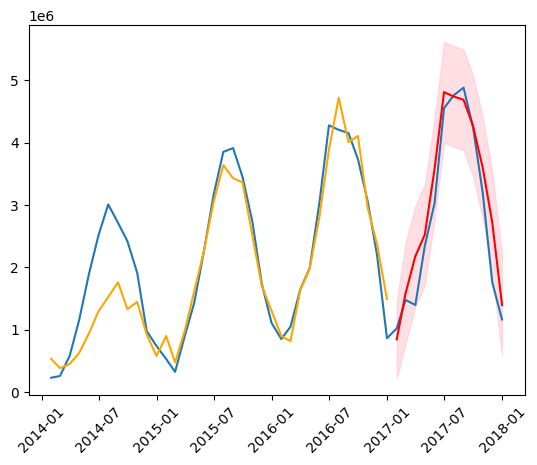

In [188]:
plt.plot(series)
plt.plot(fitted_values, 
         color = 'orange', 
         label = 'forecast')
plt.plot(forecast_mean, color = 'red')
plt.fill_between(forecast_mean.index,
                conf_int_df['lower tripduration'],
                conf_int_df['upper tripduration'],
                color = 'pink',
                alpha = 0.5)
plt.xticks(rotation = 45);

In [189]:
results_df = log_experiment(results_df, "SARIMA(1,0,0)x(0,1,0,12) intercept", test, forecast_mean)

In [190]:
results_df 

,Model,MAE,RMSE,MAPE
0,AR_1,1434384.82,1881946.06,0.41
1,AR_2,1140284.63,1254249.78,0.54
2,MA_1,1264229.03,1576758.78,0.42
3,"ARMA_(1,1,1)",4900807.84,5275637.72,1.87
4,"SARIMA(2, 1, 0)x(1, 0, 0, 12)",2498350.29,2655982.78,0.98
5,"SARIMA(1,0,0)x(0,1,0,12) intercept",322713.57,430094.30,0.17


## Exogenous variables

Passing an exogenous feature (temperature) into a SARIMAX model via the exog parameter for both training and forecasting.

Bicycle rentals are heavily driven by weather. By giving the model future knowledge of expected temperatures (exog_test), it can dynamically adjust its rental volume forecasts for unusually hot or cold months.

In [191]:
temperature_series = bicycles_date['temperature'].resample('ME').mean()
temperature_series .head()

starttime
2014-01-31   18.12
2014-02-28   19.38
2014-03-31   33.59
2014-04-30   51.29
2014-05-31   64.40
Freq: ME, Name: temperature, dtype: float64

In [192]:
temperature_df = temperature_series.reset_index()
temperature_df.set_index('starttime', inplace=True)
temperature_df.head()

,temperature
starttime,
2014-01-31,18.12
2014-02-28,19.38
2014-03-31,33.59
2014-04-30,51.29
2014-05-31,64.40


In [193]:
train_other_regressors = temperature_df['temperature'][:'2016-12-31']
test_other_regressors = temperature_df['temperature']['2017-01-31':]

In [194]:
print(train.shape)
print(train_other_regressors.shape)

(36,)
(36,)


In [195]:
train_other_regressors

starttime
2014-01-31   18.12
2014-02-28   19.38
2014-03-31   33.59
2014-04-30   51.29
2014-05-31   64.40
2014-06-30   73.81
2014-07-31   73.68
2014-08-31   75.70
2014-09-30   66.59
2014-10-31   53.58
2014-11-30   35.30
2014-12-31   32.83
2015-01-31   23.80
2015-02-28   16.98
2015-03-31   38.08
2015-04-30   52.62
2015-05-31   63.40
2015-06-30   70.07
2015-07-31   75.27
2015-08-31   74.42
2015-09-30   71.17
2015-10-31   56.66
2015-11-30   46.51
2015-12-31   39.40
2016-01-31   26.03
2016-02-29   32.13
2016-03-31   45.32
2016-04-30   50.49
2016-05-31   63.58
2016-06-30   75.26
2016-07-31   78.34
2016-08-31   78.07
2016-09-30   72.03
2016-10-31   59.44
2016-11-30   48.64
2016-12-31   26.14
Name: temperature, dtype: float64

In [196]:
model = SARIMAX(endog=train,
                exog = np.array(train_other_regressors),
              order=(1, 0, 0),
              seasonal_order=(0, 1, 0, 12), 
                trend = 'c' #the intercept
               )
results = model.fit()

In [197]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                     SARIMAX Results                                      
==========================================================================================
Dep. Variable:                       tripduration   No. Observations:                   36
Model:             SARIMAX(1, 0, 0)x(0, 1, 0, 12)   Log Likelihood                -335.767
Date:                            Wed, 09 Sep 2026   AIC                            679.534
Time:                                    11:16:38   BIC                            684.246
Sample:                                01-31-2014   HQIC                           680.784
                                     - 12-31-2016                                         
Covariance Type:                              opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept   1.827e+05   6.97e+04      2.620      0.009    4.61e+04    3.19e+05
x1          5.897e+04   8556.855      6.892      0.000    4.22e+04    7.57e+04
ar.L1          0.5097      0.112      4.548      0.000       0.290       0.729
sigma2      7.841e+10      0.021   3.69e+12      0.000    7.84e+10    7.84e+10
===================================================================================
Ljung-Box (L1) (Q):                   0.67   Jarque-Bera (JB):                 0.14
Prob(Q):                              0.41   Prob(JB):                         0.93
Heteroskedasticity (H):               0.43   Skew:                             0.11
Prob(H) (two-sided):                  0.26   Kurtosis:                         2.71
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
[2] Covariance matrix is singular or near-singular, with condition number 7.54e+28. Standard errors may be unstable.
"""

In [198]:
forecast = results.get_prediction(start = '2017-01-31', 
                                  end = '2017-12-31',
                                 exog = test_other_regressors)
forecast_mean = forecast.predicted_mean
confidence_intervals = forecast.conf_int()
confidence_intervals

,lower tripduration,upper tripduration
2017-01-31,992688.87,2090354.44
2017-02-28,1371003.23,2603034.01
2017-03-31,1136568.32,2401173.54
2017-04-30,2099723.31,3372655.08
2017-05-31,2647042.54,3922128.70
2017-06-30,4053554.24,5329199.52
2017-07-31,3896610.40,5172400.90
2017-08-31,3648993.94,4924822.17
2017-09-30,3488362.18,4764200.21
2017-10-31,2776692.70,4052533.27


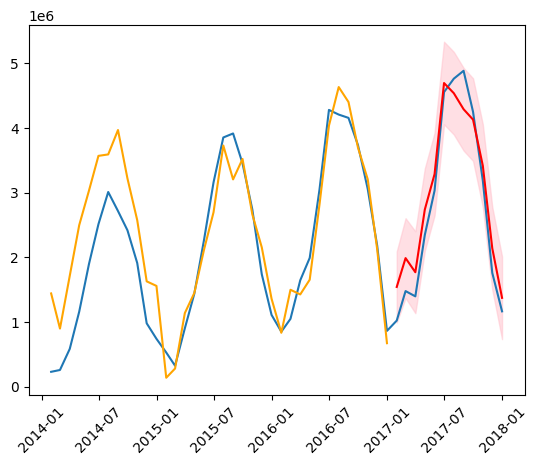

In [199]:
plt.plot(series)
plt.plot(results.fittedvalues, 
         color = 'orange', 
         label = 'forecast')
plt.plot(forecast_mean, color = 'red')
plt.fill_between(forecast_mean.index,
                confidence_intervals['lower tripduration'],
                confidence_intervals['upper tripduration'],
                color = 'pink',
                alpha = 0.5)
plt.xticks(rotation = 45);

In [200]:
results_df = log_experiment(results_df, "SARIMAX(1, 0, 0)x(0, 1, 0, 12) intercept", test, forecast_mean)

In [201]:
results_df

,Model,MAE,RMSE,MAPE
0,AR_1,1434384.82,1881946.06,0.41
1,AR_2,1140284.63,1254249.78,0.54
2,MA_1,1264229.03,1576758.78,0.42
3,"ARMA_(1,1,1)",4900807.84,5275637.72,1.87
4,"SARIMA(2, 1, 0)x(1, 0, 0, 12)",2498350.29,2655982.78,0.98
5,"SARIMA(1,0,0)x(0,1,0,12) intercept",322713.57,430094.30,0.17
6,"SARIMAX(1, 0, 0)x(0, 1, 0, 12) intercept",328677.52,360990.44,0.17


Notice how ARMA_(1,1) performs drastically worse than the simpler models (MAE jumps to 4.9 million). More parameters or combining AR and MA blindly without proper stationarity or differencing leads to disastrous, overfitted, or unstable forecasts. These models have zero awareness of the annual seasonal cycle.

Model 5:
- MAE drops from ~2.5M down to ~322K.
- RMSE drops from ~2.6M down to ~430K.
- MAPE drops to 0.17 (17%).

Adding that seasonal moving average/differencing component at lag 12 instantly locks onto the annual summer/winter rental cycles, shrinking errors to a fraction of their previous values.

- Model 5 (SARIMA without weather) has a slightly lower MAE (322,713 vs. 328,677).
- Model 6 (SARIMAX with temperature) achieves the lowest RMSE on the board (360,990.44) and matches the best MAPE (0.17).

Model 5 is a bit more accurate on average, as shown by its lower MAE. However, Model 6 has a lower RMSE, meaning it makes fewer large errors. Adding outside information like temperature helps the model avoid large errors when a month is much hotter or colder than usual. Using external factors helps make time-series models more reliable.

# Task 5

# Task 6